In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Suraj\Downloads\supplychain-iq-code\supplychain-iq\data\raw\DataCoSupplyChainDataset.csv",encoding="latin-1")

In [3]:
print(df.shape)
print(df.columns.tolist())
df.info()

(180519, 53)
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping d

In [4]:
nulls = df.isnull().sum().sort_values(ascending=False)
print(nulls.head(5))

Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
dtype: int64


In [5]:
print("Rows:", len(df))
print("Unique Orders:", df["Order Id"].nunique())

Rows: 180519
Unique Orders: 65752


In [6]:

# cLean 
clean_cols = df.columns.str.lower().str.strip()

# replce specail character with _ 
df.columns = clean_cols.str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_')

df.rename(columns={'order_date_dateorders': 'order_date', 'shipping_date_dateorders': 'shipping_date'}, inplace=True)

In [7]:
# 3. Duplicate/private  columns drop
drop_cols = [
    'order_customer_id', 'order_item_cardprod_id', 'product_category_id',
    'order_profit_per_order', 'order_item_product_price',
    'customer_email', 'customer_password', 'customer_fname', 
    'customer_lname', 'customer_street', 'product_description', 
    'product_image', 'order_zipcode'
]
df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)


In [8]:
# fix date data type into date
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y %H:%M', errors='coerce')
df['shipping_date'] = pd.to_datetime(df['shipping_date'], format='%m/%d/%Y %H:%M', errors='coerce')


In [11]:
# Feature engineering
df['delay_days'] = df['days_for_shipping_real'] - df['days_for_shipment_scheduled']
df['is_late'] = (df['delivery_status'] == 'Late delivery').astype(int)
df['is_loss'] = (df['benefit_per_order'] < 0).astype(int)

In [11]:
# EDA

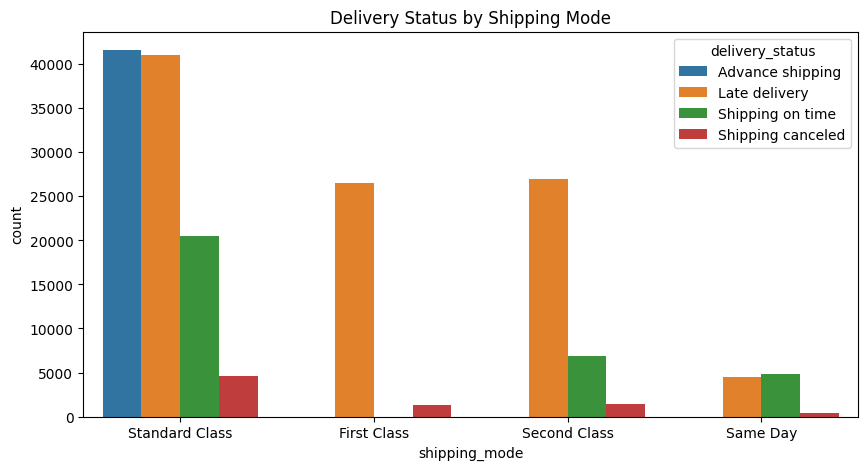

In [12]:
#Delivery Status by Shipping Mode
plt.figure(figsize=(10,5))
sns.countplot(data=df,x='shipping_mode',hue='delivery_status')
plt.title("Delivery Status by Shipping Mode")
plt.show()

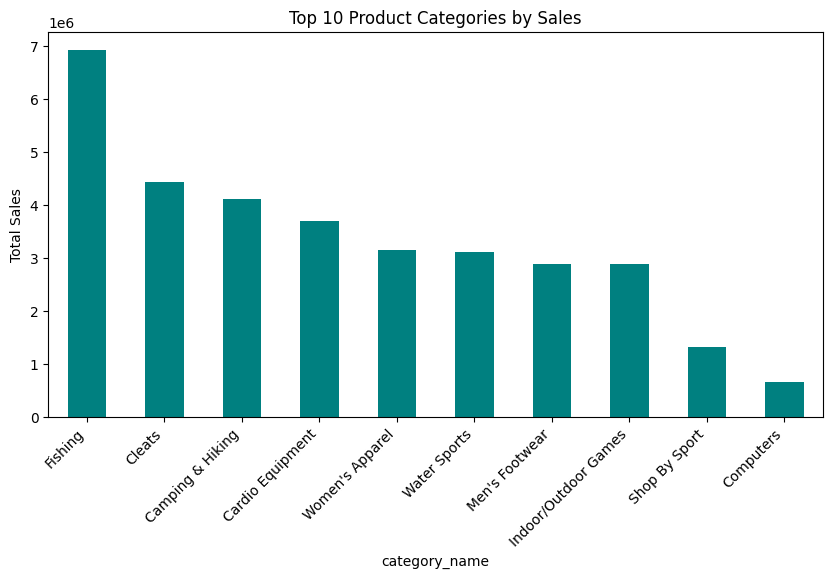

In [13]:
#Top 10 Product Categories by Sales
plt.figure(figsize=(10,5))
top_cat=df.groupby('category_name')['sales'].sum().sort_values(ascending=False).head(10)
top_cat.plot(kind='bar',color='teal')
plt.title("Top 10 Product Categories by Sales")
plt.ylabel("Total Sales")
plt.xticks(rotation=45,ha='right')
plt.show()

In [14]:
df.columns

Index(['type', 'days_for_shipping_real', 'days_for_shipment_scheduled',
       'benefit_per_order', 'sales_per_customer', 'delivery_status',
       'late_delivery_risk', 'category_id', 'category_name', 'customer_city',
       'customer_country', 'customer_id', 'customer_segment', 'customer_state',
       'customer_zipcode', 'department_id', 'department_name', 'latitude',
       'longitude', 'market', 'order_city', 'order_country', 'order_date',
       'order_id', 'order_item_discount', 'order_item_discount_rate',
       'order_item_id', 'order_item_profit_ratio', 'order_item_quantity',
       'sales', 'order_item_total', 'order_region', 'order_state',
       'order_status', 'product_card_id', 'product_name', 'product_price',
       'product_status', 'shipping_date', 'shipping_mode', 'delay_days',
       'is_late', 'is_loss'],
      dtype='object')

In [13]:
# Save clean file 
df.to_csv(r"C:/Users/Suraj/Downloads/supplychain-iq-code/supplychain-iq/data/clean/dataco_clean.csv", index=False)
print("Shape:", df.shape)

Shape: (180519, 43)
